In [164]:
import pandas as pd

In [165]:
pd.set_option('display.max_columns', None)
df = pd.read_csv('epl_final.csv')
df.head()

,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,17,8,14,4,6,6,13,12,1,2,0,0
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,17,12,10,5,7,7,19,14,1,2,0,0
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,6,16,3,9,8,4,15,21,5,3,1,0
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,6,13,4,6,5,8,11,13,1,1,0,0
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,17,12,8,6,6,4,21,20,1,3,0,0


In [166]:
df.describe()

,FullTimeHomeGoals,FullTimeAwayGoals,HalfTimeHomeGoals,HalfTimeAwayGoals,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
count,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000
mean,1.535394,1.182623,0.688273,0.518763,13.617484,10.810661,5.973134,4.693710,6.040299,4.774733,11.276333,11.765672,1.468124,1.792431,0.062473,0.085288
std,1.305432,1.157414,0.835079,0.735357,5.356424,4.696501,3.267954,2.750045,3.110619,2.749541,3.750250,3.924179,1.217190,1.288481,0.253221,0.290183
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,10.000000,7.000000,4.000000,3.000000,4.000000,3.000000,9.000000,9.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,13.000000,10.000000,6.000000,4.000000,6.000000,4.000000,11.000000,12.000000,1.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,1.000000,1.000000,17.000000,14.000000,8.000000,6.000000,8.000000,6.000000,14.000000,14.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,9.000000,5.000000,5.000000,43.000000,37.000000,24.000000,20.000000,20.000000,19.000000,33.000000,29.000000,7.000000,9.000000,3.000000,2.000000


In [167]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9380 entries, 0 to 9379
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Season             9380 non-null   str  
 1   MatchDate          9380 non-null   str  
 2   HomeTeam           9380 non-null   str  
 3   AwayTeam           9380 non-null   str  
 4   FullTimeHomeGoals  9380 non-null   int64
 5   FullTimeAwayGoals  9380 non-null   int64
 6   FullTimeResult     9380 non-null   str  
 7   HalfTimeHomeGoals  9380 non-null   int64
 8   HalfTimeAwayGoals  9380 non-null   int64
 9   HalfTimeResult     9380 non-null   str  
 10  HomeShots          9380 non-null   int64
 11  AwayShots          9380 non-null   int64
 12  HomeShotsOnTarget  9380 non-null   int64
 13  AwayShotsOnTarget  9380 non-null   int64
 14  HomeCorners        9380 non-null   int64
 15  AwayCorners        9380 non-null   int64
 16  HomeFouls          9380 non-null   int64
 17  AwayFouls          9380 n

In [168]:
df['Season'].value_counts()

Season
2000/01    380
2001/02    380
2002/03    380
2005/06    380
2006/07    380
2007/08    380
2008/09    380
2009/10    380
2010/11    380
2011/12    380
2012/13    380
2013/14    380
2014/15    380
2015/16    380
2016/17    380
2017/18    380
2018/19    380
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    350
2003/04    335
2004/05    335
Name: count, dtype: int64

### Final Standings for every Season

In [169]:
df_standings = df[~df['Season'].isin(['2003/04', '2004/05', '2024/25'])].copy() 
# Excluding season 2024/2025, 2003/2004, 2004/2005 because it doesn't have complete data (matches != 380)

df_standings["HomePts"] = df_standings["FullTimeResult"].map({"H": 3, "D": 1, "A": 0})
df_standings["AwayPts"] = df_standings["FullTimeResult"].map({"H": 0, "D": 1, "A": 3})

df_standings["HomeWin"] = (df_standings["FullTimeResult"] == "H").astype(int)
df_standings["Draw"]    = (df_standings["FullTimeResult"] == "D").astype(int)
df_standings["AwayWin"] = (df_standings["FullTimeResult"] == "A").astype(int)

home = df_standings.groupby(["Season", "HomeTeam"]).agg(
    Pts=("HomePts", "sum"),
    GF=("FullTimeHomeGoals", "sum"),
    GA=("FullTimeAwayGoals", "sum"),
    W=("HomeWin", "sum"),
    D=("Draw", "sum"),
    L=("AwayWin", "sum")
)

away = df_standings.groupby(["Season", "AwayTeam"]).agg(
    Pts=("AwayPts", "sum"),
    GF=("FullTimeAwayGoals", "sum"),
    GA=("FullTimeHomeGoals", "sum"),
    W=("AwayWin", "sum"),
    D=("Draw", "sum"),
    L=("HomeWin", "sum")
)

In [170]:
home

Pts  GF  GA   W  D   L
Season  HomeTeam                                
2000/01 Arsenal            48  45  13  15  3   1
        Aston Villa        32  27  20   8  8   3
        Bradford           19  20  29   4  7   8
        Charlton           38  31  19  11  5   3
        Chelsea            42  44  20  13  3   3
...                       ...  ..  ..  .. ..  ..
2023/24 Nott'm Forest      20  27  30   5  5   9
        Sheffield United   10  19  57   2  4  13
        Tottenham          39  38  27  13  0   6
        West Ham           29  31  28   7  8   4
        Wolves             27  26  30   8  3   8

[440 rows x 6 columns]

In [171]:
away

Pts  GF  GA  W  D   L
Season  AwayTeam                               
2000/01 Arsenal            22  18  25  5  7   7
        Aston Villa        22  19  23  5  7   7
        Bradford            7  10  41  1  4  14
        Charlton           14  19  38  3  5  11
        Chelsea            19  24  25  4  7   8
...                       ...  ..  .. .. ..  ..
2023/24 Nott'm Forest      16  22  37  4  4  11
        Sheffield United    6  16  47  1  3  15
        Tottenham          27  36  34  7  6   6
        West Ham           23  29  46  7  2  10
        Wolves             19  24  35  5  4  10

[440 rows x 6 columns]

In [172]:
home.index.names = away.index.names = ["Season", "Team"]

standings = home.add(away, fill_value=0).reset_index()
standings["GD"] = standings["GF"] - standings["GA"]

standings = standings.sort_values(["Season", "Pts", "GD", "GF"], ascending=[True, False, False, False])
standings["Pos"] = standings.groupby("Season").cumcount() + 1

In [173]:
standings

,Season,Team,Pts,GF,GA,W,D,L,GD,Pos
13,2000/01,Man United,80,79,31,24,8,6,48,1
0,2000/01,Arsenal,70,63,38,20,10,8,25,2
11,2000/01,Liverpool,69,71,39,20,9,9,32,3
9,2000/01,Leeds,68,64,43,20,8,10,21,4
8,2000/01,Ipswich,66,57,42,20,6,12,15,5
...,...,...,...,...,...,...,...,...,...,...
423,2023/24,Brentford,39,56,65,10,9,19,-9,16
435,2023/24,Nott'm Forest,36,49,67,9,9,20,-18,17
431,2023/24,Luton,26,52,85,6,8,24,-33,18
425,2023/24,Burnley,24,41,78,5,9,24,-37,19


In [174]:
standings = standings[["Season", "Pos", "Team", "W", "D", "L", "GF", "GA", "GD", "Pts"]]

In [175]:
# Checking premier league final standings in a specific season
standings[standings["Season"] == '2015/16']

,Season,Pos,Team,W,D,L,GF,GA,GD,Pts
266,2015/16,1,Leicester,23,12,3,68,36,32,81
260,2015/16,2,Arsenal,20,11,7,65,36,29,71
276,2015/16,3,Tottenham,19,13,6,69,35,34,70
268,2015/16,4,Man City,19,9,10,71,41,30,66
269,2015/16,5,Man United,19,9,10,49,35,14,66
272,2015/16,6,Southampton,18,9,11,59,41,18,63
279,2015/16,7,West Ham,16,14,8,65,51,14,62
267,2015/16,8,Liverpool,16,12,10,63,50,13,60
273,2015/16,9,Stoke,14,9,15,41,55,-14,51
263,2015/16,10,Chelsea,12,14,12,59,53,6,50


In [176]:
standings["Season"].unique()

<StringArray>
['2000/01', '2001/02', '2002/03', '2005/06', '2006/07', '2007/08', '2008/09',
 '2009/10', '2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16',
 '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23',
 '2023/24']
Length: 22, dtype: str

In [177]:
# Top 3 teams in every season
seasons = standings["Season"].unique()
for season in seasons:
    print(standings[standings["Season"] == season].head(3))
    print("")

     Season  Pos        Team   W   D  L  GF  GA  GD  Pts
13  2000/01    1  Man United  24   8  6  79  31  48   80
0   2000/01    2     Arsenal  20  10  8  63  38  25   70
11  2000/01    3   Liverpool  20   9  9  71  39  32   69

     Season  Pos        Team   W  D  L  GF  GA  GD  Pts
20  2001/02    1     Arsenal  26  9  3  79  36  43   87
32  2001/02    2   Liverpool  24  8  6  67  30  37   80
33  2001/02    3  Man United  24  5  9  87  45  42   77

     Season  Pos        Team   W  D   L  GF  GA  GD  Pts
52  2002/03    1  Man United  25  8   5  74  34  40   83
40  2002/03    2     Arsenal  23  9   6  85  42  43   78
54  2002/03    3   Newcastle  21  6  11  63  48  15   69

     Season  Pos        Team   W  D  L  GF  GA  GD  Pts
66  2005/06    1     Chelsea  29  4  5  72  22  50   91
71  2005/06    2  Man United  25  8  5  72  34  38   83
69  2005/06    3   Liverpool  25  7  6  57  25  32   82

     Season  Pos        Team   W   D   L  GF  GA  GD  Pts
90  2006/07    1  Man United  28  

### Premier league champion from each season

In [178]:
standings[standings['Pos'] == 1][['Season', 'Team']]

,Season,Team
13,2000/01,Man United
20,2001/02,Arsenal
52,2002/03,Man United
66,2005/06,Chelsea
90,2006/07,Man United
111,2007/08,Man United
130,2008/09,Man United
146,2009/10,Chelsea
171,2010/11,Man United
188,2011/12,Man City


In [179]:
standings_barplot = standings[standings['Pos'] == 1][['Season', 'Team']]
standings_barplot = standings_barplot.pivot_table(index='Team', values='Team', aggfunc='count')
standings_barplot = standings_barplot.rename(columns={"Team": "Titles"})
standings_barplot = standings_barplot.sort_values('Titles', ascending=False)
standings_barplot

,Titles
Team,
Man City,8
Man United,7
Chelsea,4
Arsenal,1
Liverpool,1
Leicester,1


### Insights

#### Insight 1

<Axes: title={'center': 'Premier League Titles by Club from 22 seasons'}, xlabel='Team'>

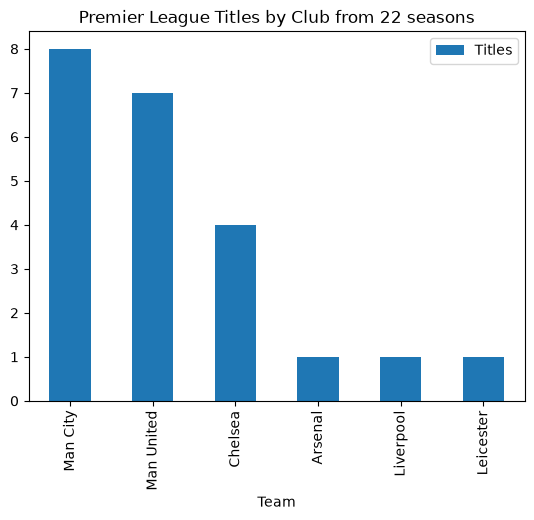

In [180]:
# Making bar plot to see which teams have won the premier league (and how many)
standings_barplot.plot(kind='bar', title='Premier League Titles by Club from 22 seasons')

- Important Reminder: Premier League champion in season 2003/04, 2004/05, 2024/2025 is not included, because the dataset in those seasons are missing some matches

- In 22 seasons, Man City is the most successful team in the Premier League by winning 8 premier league titles. Followed by Man United which has 7 premier league titles.

#### Insight 2

In [181]:
# Checking total goals scored by every team in premier league since 2000/01
most_goals = standings.pivot_table(index='Team', values='GF', aggfunc='sum')
most_goals.sort_values('GF', ascending=False).head(10)

,GF
Team,
Arsenal,1580
Liverpool,1570
Man City,1566
Man United,1555
Chelsea,1514
Tottenham,1373
Everton,1086
West Ham,1010
Newcastle,997


Based on 22 seasons, Arsenal scored the most goals in Premier League with 1580 goals. Followed by Liverpool with 1570 goals and Man City with 1566 goals.

#### Insight 3

<Axes: title={'center': 'Match results by season'}, xlabel='Season'>

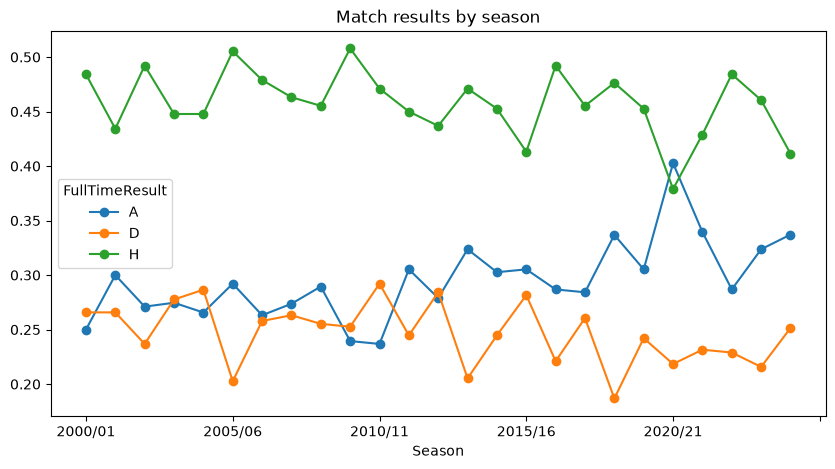

In [182]:
# Making plot to see match win results per season
res = df.groupby("Season")["FullTimeResult"].value_counts(normalize=True).unstack()
res.plot(marker="o", figsize=(10, 5), title="Match results by season")

From the plot, it can be seen that in most season, home teams won more often than away teams. Usually/in most seasons, home teams won about 45-50% of their matches, while away teams won about 25-33%. The only exception was in 2020/21, when games were played without fans (because of covid-19 pandemic), and away teams won more often than home teams. This can indicate that having fans in the stadium is an important reason why teams play better at home.

#### Insight 4

In [183]:
standings.groupby('Team')[["W", "D", "L"]].sum().head(5)

,W,D,L
Team,,,
Arsenal,473,184,179
Aston Villa,236,203,283
Birmingham,50,56,84
Blackburn,119,87,136
Blackpool,10,9,19


In [184]:
# Checking win rate of every team
team_win_rate = standings.groupby('Team')[["W", "D", "L"]].sum()

win_rate = ((team_win_rate.W/(team_win_rate.W + team_win_rate.D + team_win_rate.L)))
win_rate = win_rate.round(5)

team_win_rate['win_rate'] = win_rate
team_win_rate.sort_values('win_rate', ascending=False).head(10)

,W,D,L,win_rate
Team,,,,
Man United,503,172,161,0.60167
Man City,462,141,195,0.57895
Liverpool,474,200,162,0.56699
Arsenal,473,184,179,0.56579
Chelsea,468,194,174,0.55981
Tottenham,404,187,245,0.48325
Ipswich,29,15,32,0.38158
Leeds,86,51,91,0.37719
Everton,315,230,291,0.37679


Manchester United has the highest win rate at 60.167%, followed by Manchester City (57.895%) and Liverpool (56.699%), highlighting the strong performance of these top clubs. In contrast, other team such as Leicester, Everton, and Leeds have win rates of around 36–38%. These results indicate differences in team performance, although the number of matches played and the period each team participated in the Premier League may affect the comparison.

#### Insight 5

In [185]:
standings[standings['Team'] == 'Man United']

,Season,Pos,Team,W,D,L,GF,GA,GD,Pts
13,2000/01,1,Man United,24,8,6,79,31,48,80
33,2001/02,3,Man United,24,5,9,87,45,42,77
52,2002/03,1,Man United,25,8,5,74,34,40,83
71,2005/06,2,Man United,25,8,5,72,34,38,83
90,2006/07,1,Man United,28,5,5,83,27,56,89
111,2007/08,1,Man United,27,6,5,80,22,58,87
130,2008/09,1,Man United,28,6,4,68,24,44,90
152,2009/10,2,Man United,27,4,7,86,28,58,85
171,2010/11,1,Man United,23,11,4,78,37,41,80
189,2011/12,2,Man United,28,5,5,89,33,56,89


<Axes: title={'center': 'Man United League Points Performance'}, xlabel='Season'>

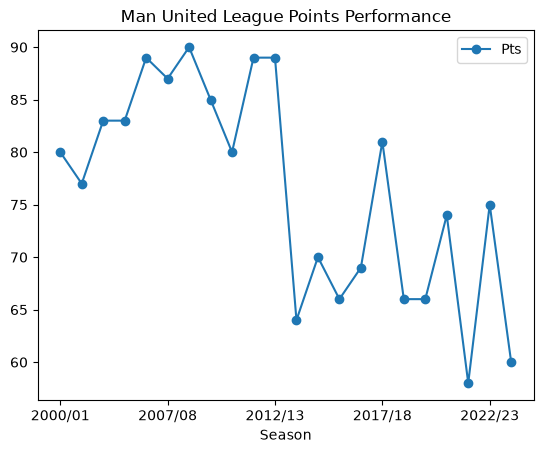

In [186]:
# Checking specific team performance by Pts
team_performance = standings[standings['Team'] == 'Man United']

team_performance.plot(kind='line', marker='o', x='Season', y='Pts', title='Man United League Points Performance')

Manchester United performed very well and often earned 80 points or more each season before Sir Alex Ferguson retired in 2013. After his retirement, the team's performance declined and became less consistent. The club rarely reached 80 points again, showing that Manchester United struggled to maintain the same level of success as during Ferguson era.

#### Insight 6

<Axes: title={'center': 'Relationship between GD and Final Position'}, xlabel='GD', ylabel='Pos'>

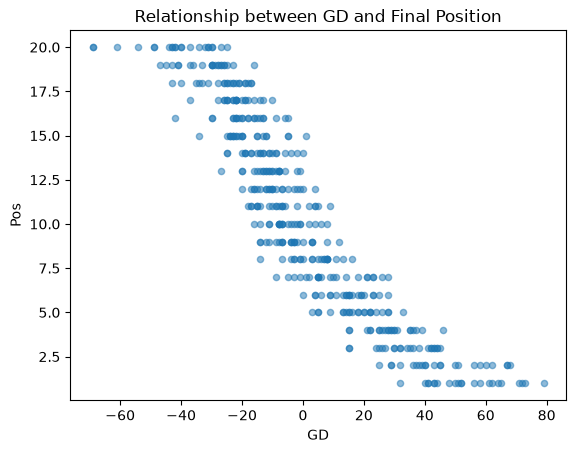

In [187]:
# Relationship between 2 variables -> checking the relationship between goal difference and final position
standings.plot.scatter(x='GD', y='Pos', alpha=0.5, title='Relationship between GD and Final Position')

The scatter plot shows that teams with a higher Goal Difference (GD) usually finish in better league positions. Teams with a positive GD tend to rank near the top, while teams with a negative GD often finish near the bottom. This suggests that scoring more goals than they concede is an important factor in a team's success.

#### Insight 7

In [188]:
# Average position and pts
standings.groupby('Team')[['Pos', 'Pts']].mean().sort_values('Pos', ascending=True).head(20)

,Pos,Pts
Team,,
Man United,3.090909,76.409091
Arsenal,3.818182,72.863636
Chelsea,4.000000,72.636364
Liverpool,4.090909,73.727273
Man City,4.952381,72.714286
Tottenham,5.954545,63.590909
Everton,9.545455,53.409091
Leicester,10.363636,50.454545
Newcastle,10.700000,50.200000


The table shows that the traditional Big Six teams generally have better average league positions and points than the other teams. Manchester United, Arsenal, Chelsea, Liverpool, and Manchester City have particularly strong results, while Tottenham also performs better than most other teams. This is probably one of the reasons they are called the “Big Six,” as they have historically been among the most competitive clubs in the Premier League over the past 20 years.